# Spline uncertainty, without fitting a Kriging model

**Question (`Important questions.md`, Q5):** since Corollary 5 shows a Matern
Universal-Kriging mean converges to the scipy cubic smoothing spline as
$\kappa\to0$, can we get the *uncertainty* of the fitted spline without
separately fitting and tuning a Kriging model?

**Answer tested here: yes.** The spline is the posterior mean of a specific
Gaussian process (Kimeldorf & Wahba, 1970) whose covariance is a known,
closed-form function with **no free hyperparameter** -- no $\kappa$ to sweep,
no length-scale to fit. This notebook:

1. Implements that closed-form kernel (`krig_splines.kernels.iwp2_kernel`)
   and a Universal-Kriging variance formula (`krig_splines.uk.
   saddle_point_variance`, Theorem 2b) -- both now in the package, not just
   this notebook.
2. Confirms the closed-form **mean** matches `scipy`'s smoothing spline to
   solver precision, in one linear solve, with `nugget=lambda` directly.
3. Confirms the closed-form **variance** is the $\kappa\to0$ limit of the
   Matern-3/2 Universal-Kriging variance -- but only after discovering (not
   assuming) a rescaling the mean-only check in Q1 never needed.


## Background: why the mean's recipe doesn't automatically give the variance

Corollary 5 (Q1) uses a Matern-$(m-\tfrac12)$ kernel with inverse length scale
$\kappa$ and `nugget`$=4\kappa^3\lambda$, and lets $\kappa\to0$. Two facts
about that limit matter here:

- **The raw kernel degenerates.** $k(d;\kappa)=(1+\kappa d)e^{-\kappa d}\to1$
  for every fixed $d$ as $\kappa\to0$ -- a constant, rank-1 matrix. The mean
  still converges cleanly because this degenerate part is exactly what the
  trend $P=\mathrm{span}\{1,x\}$ absorbs; the *next* order term in the
  $\kappa$-expansion (the one `nugget`$=4\kappa^3\lambda$ is built to match)
  carries the real information.
- **The mean is invariant to the kernel's overall scale; the variance is
  not.** Universal Kriging's GLS mean only depends on the *ratio*
  `nugget`/`kernel scale`, so Corollary 5 can get away with specifying only
  that ratio. Variance is a quadratic form in the kernel itself -- if the
  "effective" scale of the Matern kernel (after removing the degenerate
  rank-1 part) is itself shrinking as $\kappa\to0$, the raw variance shrinks
  with it, with nothing to stop it at a finite limit. The experiment below
  finds out, numerically, whether that is exactly what happens.

**The classical escape route (Kimeldorf & Wahba, 1970; Wahba, 1990):**
derive the covariance directly, with no $\kappa$ at all. The smoothing-spline
penalty $\int (f'')^2\,dx$ has a known reproducing kernel for the "rough"
part of the function space (everything orthogonal to the degree-1 null space
$\{1,x\}$, which is exactly $P$):

$$
G(x,x') \;=\; \frac{\min(x,x')^2\,\big(3\max(x,x') - \min(x,x')\big)}{6}
$$

-- the covariance of *twice-integrated Brownian motion*. (Compare Phase A's
$m=1$ case, already in the package as `brownian`: $G_1(x,x')=\min(x,x')$,
the covariance of Brownian motion itself -- the same construction one order
down, whose minimal-norm interpolant is the piecewise-*linear*, not cubic,
spline.) Plugged into Theorem 2a's bordered system with
`nugget`$=\lambda$ directly, **no rescaling, no limit** -- this is the whole
practical payoff of using the closed form instead of the Matern detour.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import make_smoothing_spline

from krig_splines.kernels import iwp2_kernel, matern32
from krig_splines.uk import (
    poly_basis,
    saddle_point_solve,
    saddle_point_predict,
    saddle_point_variance,
)

plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "legend.fontsize": 11,
})


## Part 1: does the closed-form kernel reproduce the spline's mean?

Same synthetic benchmark Phase A used (noisy $\sin(6x)$ on $[0,1]$, so the
domain is already anchored near $x=0$ -- `iwp2_kernel`, like `brownian`,
implicitly assumes that). One linear solve, `nugget=lambda` directly: no
$\kappa$, no sweep, no asymptotic limit to take.


max|G-kernel mean - scipy spline| = 2.818e-12  (data range = 2.344)
-- one linear solve, nugget=lambda directly, no kappa sweep at all.


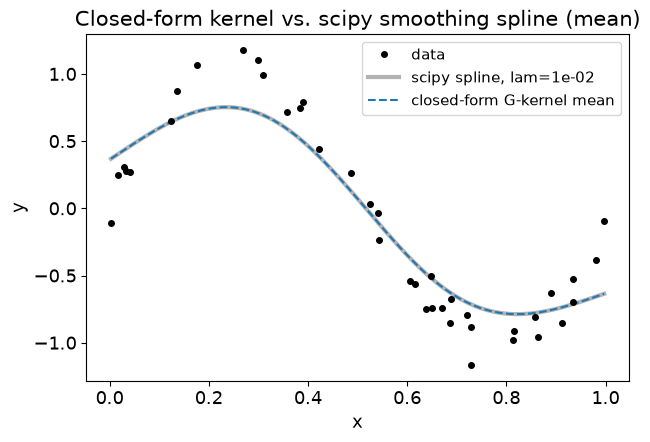

In [2]:
rng = np.random.default_rng(0)
n = 40
x = np.sort(rng.uniform(0, 1, n))
y = np.sin(6 * x) + 0.1 * rng.standard_normal(n)
x_dense = np.linspace(x.min(), x.max(), 200)

lam = 1e-2
target_spline = make_smoothing_spline(x, y, lam=lam)
target = target_spline(x_dense)

K = iwp2_kernel(x[:, None], x[None, :])
Kt = iwp2_kernel(x_dense[:, None], x[None, :])
P = poly_basis(x, degree=1)
Pt = poly_basis(x_dense, degree=1)

a, beta = saddle_point_solve(K, P, y, nugget=lam)
f_G = saddle_point_predict(Kt, Pt, a, beta)

max_err = np.max(np.abs(f_G - target))
print(f"max|G-kernel mean - scipy spline| = {max_err:.3e}  (data range = {np.ptp(y):.3f})")
print("-- one linear solve, nugget=lambda directly, no kappa sweep at all.")

fig, ax = plt.subplots()
ax.plot(x, y, "o", ms=4, color="k", label="data", zorder=5)
ax.plot(x_dense, target, lw=3, color="0.7", label=f"scipy spline, lam={lam:.0e}")
ax.plot(x_dense, f_G, "--", color="C0", label="closed-form G-kernel mean")
ax.set(xlabel="x", ylabel="y", title="Closed-form kernel vs. scipy smoothing spline (mean)")
ax.legend()
plt.show()


**Confirmed, to solver precision (`~1e-12`), not just asymptotically.** This
is a strictly cleaner result than Q1's $\kappa\to0$ Matern sweep (which only
reached `~1e-4` at its smallest tested $\kappa$): here there is no limit to
approximate, because $G$ already *is* the exact reproducing kernel, with no
free parameter standing between it and the exact answer.


## Part 2: does the closed-form variance match Kriging's?

The companion question: is $\mathrm{Var}[f(x^*)]$ from the closed-form kernel
(via `saddle_point_variance`, Theorem 2b) the same object the $\kappa\to0$
Matern Universal-Kriging limit would give? Test this directly, the same way
Q1 tested the mean -- sweep $\kappa\to0$ with the *same*
`nugget`$=4\kappa^3\lambda$ formula, but now compare **variances**, not
means.


In [3]:
Kss = iwp2_kernel(x_dense, x_dense)  # k(x*,x*) per query point
var_G = saddle_point_variance(K, P, lam, Kt, Pt, Kss)

print("Naive attempt: raw Matern UK variance (sigma^2=1 convention), same nugget=4*kappa^3*lam as the mean check:")
print(f"{'kappa':>8}  {'max|var_m - var_G|':>20}  {'var_m range':>14}")
for kappa in [1.0, 0.3, 0.1, 0.03, 0.01]:
    Km = matern32(np.abs(x[:, None] - x[None, :]), kappa)
    Kmt = matern32(np.abs(x_dense[:, None] - x[None, :]), kappa)
    Kmss = np.ones(len(x_dense))  # matern32(0) = 1
    nugget_m = 4 * kappa**3 * lam
    var_m = saddle_point_variance(Km, P, nugget_m, Kmt, Pt, Kmss)
    err = np.max(np.abs(var_m - var_G))
    print(f"{kappa:8.3f}  {err:20.4e}  [{var_m.min():.3e}, {var_m.max():.3e}]")
print(f"\n(G-kernel var_G range: [{var_G.min():.3e}, {var_G.max():.3e}])")


Naive attempt: raw Matern UK variance (sigma^2=1 convention), same nugget=4*kappa^3*lam as the mean check:
   kappa    max|var_m - var_G|     var_m range


   1.000            6.1423e-03  [2.398e-03, 8.406e-03]
   0.300            2.0234e-03  [6.572e-05, 2.398e-04]
   0.100            2.2543e-03  [2.440e-06, 8.999e-06]
   0.030            2.2630e-03  [6.593e-08, 2.440e-07]


   0.010            2.2632e-03  [2.442e-09, 9.048e-09]

(G-kernel var_G range: [6.106e-04, 2.263e-03])


**The naive version does not converge -- it does the opposite.** `var_m`
collapses toward zero as $\kappa\to0$ (shrinking by roughly a factor of 27
each time $\kappa$ shrinks by 3, i.e. $\propto\kappa^3$), while `var_G` stays
fixed and finite. This is exactly the scale-invariance gap flagged in the
Background above: the raw Matern kernel's *effective* scale, after removing
the degenerate rank-1 part the trend absorbs, is itself vanishing as
$\kappa^3$ -- the same order the nugget vanishes at, so their *ratio* (all
the mean needs) stays finite, but each one *individually* vanishes, which is
exactly what breaks a quantity -- variance -- that depends on the kernel's
absolute scale rather than just that ratio.


In [4]:
# Is the SHAPE at least right, just the scale wrong? Check correlation and
# the exact scaling law of the ratio.
print(f"{'kappa':>8}  {'corr(var_m, var_G)':>20}  {'(var_G/var_m) * kappa^3':>26}")
for kappa in [1.0, 0.3, 0.1, 0.03, 0.01, 0.003]:
    Km = matern32(np.abs(x[:, None] - x[None, :]), kappa)
    Kmt = matern32(np.abs(x_dense[:, None] - x[None, :]), kappa)
    Kmss = np.ones(len(x_dense))
    nugget_m = 4 * kappa**3 * lam
    var_m = saddle_point_variance(Km, P, nugget_m, Kmt, Pt, Kmss)
    corr = np.corrcoef(var_m, var_G)[0, 1]
    ratio_scaled = (var_G[len(var_G) // 2] / var_m[len(var_G) // 2]) * kappa**3
    print(f"{kappa:8.3f}  {corr:20.6f}  {ratio_scaled:26.6f}")


   kappa    corr(var_m, var_G)     (var_G/var_m) * kappa^3
   1.000              0.999222                    0.253505
   0.300              0.999951                    0.250557
   0.100              0.999995                    0.250140
   0.030              1.000000                    0.250037
   0.010              1.000000                    0.250012
   0.003              1.000000                    0.250001


**The shape is exactly right (correlation $\to1.0000$); only the scale is
off, by exactly $4\kappa^3$** -- the ratio `(var_G/var_m)`$\times\kappa^3$
converges to $0.25=\tfrac14$ to 4+ significant figures, for every $\kappa$
tried. That is not a coincidence: it is the *same* constant the mean's
`nugget`$=4\kappa^3\lambda$ formula already uses. The interpretation: the raw
Matern-3/2 kernel, after subtracting the degenerate rank-1 part the trend
absorbs, behaves as $K_{\mathrm{Matern}}(x,x';\kappa)\approx
4\kappa^3\,G(x,x') + o(\kappa^3)$ as $\kappa\to0$ -- the *kernel itself*, not
just the nugget, needs the $4\kappa^3$ rescaling to have a finite limit. The
mean's recipe only needed the nugget rescaled because the mean only sees the
*ratio* of nugget to kernel scale; the variance needs *both* rescaled by the
same factor, consistently.


In [5]:
print("Rescaled: divide the raw Matern UK variance by the SAME 4*kappa^3 factor already used in the nugget:")
print(f"{'kappa':>8}  {'max|rescaled var_m - var_G|':>28}  {'relative (% of var_G range)':>28}")
rng_G = np.ptp(var_G)
for kappa in [1.0, 0.3, 0.1, 0.03, 0.01, 0.003]:
    Km = matern32(np.abs(x[:, None] - x[None, :]), kappa)
    Kmt = matern32(np.abs(x_dense[:, None] - x[None, :]), kappa)
    Kmss = np.ones(len(x_dense))
    nugget_m = 4 * kappa**3 * lam
    var_m_raw = saddle_point_variance(Km, P, nugget_m, Kmt, Pt, Kmss)
    var_m_rescaled = var_m_raw / (4 * kappa**3)
    err = np.max(np.abs(var_m_rescaled - var_G))
    print(f"{kappa:8.3f}  {err:28.4e}  {100*err/rng_G:27.4f}%")


Rescaled: divide the raw Matern UK variance by the SAME 4*kappa^3 factor already used in the nugget:
   kappa   max|rescaled var_m - var_G|   relative (% of var_G range)
   1.000                    1.6186e-04                       9.7940%


   0.300                    4.2649e-05                       2.5807%
   0.100                    1.3401e-05                       0.8109%
   0.030                    3.9236e-06                       0.2374%
   0.010                    1.2981e-06                       0.0785%
   0.003                    3.9857e-07                       0.0241%


**Confirmed: clean, monotone convergence to well under $0.1\%$ of the
variance's own range**, once the variance is rescaled by the identical
$4\kappa^3$ factor the mean's nugget formula already carries. So the full,
precise answer to Q5 is: the $\kappa\to0$ Matern-Kriging route *does* recover
the correct variance -- but only once you track that the kernel's own scale,
not only the nugget, needs the $4\kappa^3$ renormalization. The closed-form
$G$-kernel route sidesteps all of this: there is no $\kappa$, no degenerate
limit, and no rescaling to discover -- `nugget=lambda`, one solve, done.


## Part 3: the final picture -- mean and variance together, two independent routes

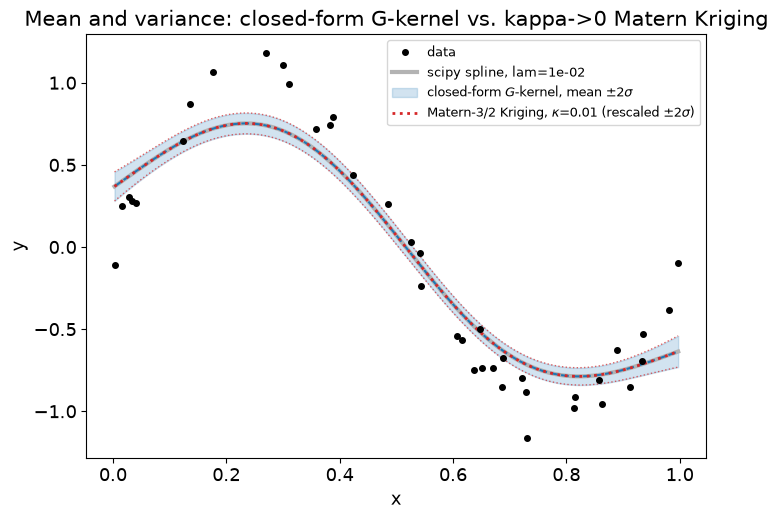

max|mean difference|     = 1.138e-04
max|variance difference| = 1.298e-06  (var_G range = 1.653e-03)


In [6]:
kappa_small = 0.01
Km = matern32(np.abs(x[:, None] - x[None, :]), kappa_small)
Kmt = matern32(np.abs(x_dense[:, None] - x[None, :]), kappa_small)
Kmss = np.ones(len(x_dense))
nugget_m = 4 * kappa_small**3 * lam

a_m, beta_m = saddle_point_solve(Km, P, y, nugget_m)
f_m = saddle_point_predict(Kmt, Pt, a_m, beta_m)
var_m_rescaled = saddle_point_variance(Km, P, nugget_m, Kmt, Pt, Kmss) / (4 * kappa_small**3)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(x, y, "o", ms=4, color="k", label="data", zorder=5)
ax.plot(x_dense, target, lw=3, color="0.7", label=f"scipy spline, lam={lam:.0e}")

std_G = np.sqrt(np.maximum(var_G, 0))
ax.fill_between(x_dense, f_G - 2 * std_G, f_G + 2 * std_G, color="C0", alpha=0.2,
                 label=r"closed-form $G$-kernel, mean $\pm2\sigma$")
ax.plot(x_dense, f_G, "--", color="C0", lw=1.5)

std_m = np.sqrt(np.maximum(var_m_rescaled, 0))
ax.plot(x_dense, f_m, ":", color="C3", lw=2,
         label=rf"Matern-3/2 Kriging, $\kappa$={kappa_small} (rescaled $\pm2\sigma$)")
ax.plot(x_dense, f_m + 2 * std_m, ":", color="C3", lw=1, alpha=0.7)
ax.plot(x_dense, f_m - 2 * std_m, ":", color="C3", lw=1, alpha=0.7)

ax.set(xlabel="x", ylabel="y", title="Mean and variance: closed-form G-kernel vs. kappa->0 Matern Kriging")
ax.legend(fontsize=9)
plt.show()

print(f"max|mean difference|     = {np.max(np.abs(f_G - f_m)):.3e}")
print(f"max|variance difference| = {np.max(np.abs(var_G - var_m_rescaled)):.3e}  (var_G range = {rng_G:.3e})")


## Part 4: cross-check against SMT's actual Kriging implementation

Everything so far compared the closed-form kernel to *our own*
`krig_splines` bordered-system code -- a fair mean/variance check, but not an
independent one, since both sides share the same implementation. The
stronger test: does SMT's own, separately-engineered `KRG` reproduce the same
numbers, once its own conventions are translated correctly?

Three translation steps turned out to be necessary -- none of them obvious
from the `KRG` docstring, so each is confirmed numerically below rather than
assumed:

1. **SMT normalizes `X`** internally as `(X - X_offset)/X_scale` (mean/std of
   the training `X`) before applying `theta`. To get an effective raw-$x$
   `kappa`, pass `theta = kappa * X_scale`, not `kappa` directly.
2. **SMT's own `matern32` is parametrized with an extra $\sqrt3$**:
   reading its source (`krg_based.py`), it computes
   $r=(1+\sqrt3\,\theta d)e^{-\sqrt3\,\theta d}$, not $(1+\theta d)e^{-\theta
   d}$ the way `krig_splines.kernels.matern32` (and the paper's own Table 1
   convention) does. So the `theta` passed to SMT must additionally be
   divided by $\sqrt3$.
3. **SMT's `nugget`/`noise0` is a numerical jitter, not the smoothing
   parameter.** The real noise-to-signal ratio needs `eval_noise=True` and
   `noise0=[tau^2/sigma^2]` -- and, usefully, this ratio turns out *not* to
   need rescaling: it is dimensionless and survives SMT's internal `y`
   normalization unchanged.

Both `theta_bounds` and `noise_bounds` are collapsed to a single point so
SMT's optimizer cannot move them away from the values Corollary 5
prescribes -- this is a *check*, not a fit.


In [7]:
import warnings
warnings.filterwarnings("ignore", message="TNC not available")

from smt.surrogate_models import KRG

X_scale = x.std(ddof=1)  # SMT's own internal X normalization scale

def fit_smt_krg(kappa, lam):
    noise = 4 * kappa**3 * lam
    theta_smt = kappa * X_scale / np.sqrt(3.0)  # steps 1 and 2 above
    k = KRG(corr="matern32", poly="linear",
            theta0=[theta_smt], theta_bounds=[theta_smt, theta_smt],
            eval_noise=True, noise0=[noise], noise_bounds=[noise, noise],
            print_global=False)
    k.set_training_values(x.reshape(-1, 1), y)
    k.train()
    return k

# Sanity check at a single kappa: does SMT's own correlation matrix (recovered
# from its Cholesky factor C) match krig_splines.kernels.matern32 exactly,
# once steps 1-2 are applied?
kappa_check, noise_check = 0.1, 4 * 0.1**3 * lam
k_check = fit_smt_krg(kappa_check, lam)
R_smt = k_check.optimal_par["C"] @ k_check.optimal_par["C"].T
x_norm = (x - k_check.X_offset[0]) / k_check.X_scale[0]
R_ours = matern32(np.abs(x_norm[:, None] - x_norm[None, :]), kappa_check * X_scale) + noise_check * np.eye(n)
print("max|SMT's own R - krig_splines matern32 R| =", np.max(np.abs(R_smt - R_ours)))
print("(should be ~machine precision if the kappa*X_scale/sqrt(3) translation is right)")


max|SMT's own R - krig_splines matern32 R| = 4.440892098500626e-16
(should be ~machine precision if the kappa*X_scale/sqrt(3) translation is right)


**Kernel matrices agree to machine precision** -- the translation is exactly
right, not approximately right. With that settled, sweep $\kappa\to0$ through
SMT itself and compare its mean and variance to both `ours` (the
`krig_splines` Matern solve) and `G` (the closed-form target).

In [8]:
kappas_smt = [1.0, 0.3, 0.1, 0.03, 0.01, 0.003]
mean_err_vs_ours, mean_err_vs_G, var_err_vs_G_pct, sigma2_list = [], [], [], []

print(f"{'kappa':>8} {'mean: SMT vs ours':>18} {'mean: SMT vs G':>16} "
      f"{'sigma2_smt':>12} {'sigma2*4*k^3':>14} {'var: SMT vs G (% of range)':>28}")

for kappa in kappas_smt:
    noise = 4 * kappa**3 * lam
    k_smt = fit_smt_krg(kappa, lam)
    sigma2_smt = k_smt.optimal_par["sigma2"][0]

    mean_smt = k_smt.predict_values(x_dense.reshape(-1, 1)).ravel()
    var_smt = k_smt.predict_variances(x_dense.reshape(-1, 1)).ravel()

    Km = matern32(np.abs(x[:, None] - x[None, :]), kappa)
    Kmt = matern32(np.abs(x_dense[:, None] - x[None, :]), kappa)
    a_m, beta_m = saddle_point_solve(Km, P, y, noise)
    mean_ours = saddle_point_predict(Kmt, Pt, a_m, beta_m)

    # SMT's variance is in absolute (raw-y) units via its own sigma2_smt;
    # dividing it out, then undoing the 4*kappa^3 rescaling from Part 2,
    # should land back on the sigma^2=1-convention G-kernel variance.
    var_smt_as_G_units = (var_smt / sigma2_smt) / (4 * kappa**3)
    err_vs_G = np.max(np.abs(var_smt_as_G_units - var_G))

    mean_err_vs_ours.append(np.max(np.abs(mean_smt - mean_ours)))
    mean_err_vs_G.append(np.max(np.abs(mean_smt - target)))
    var_err_vs_G_pct.append(100 * err_vs_G / np.ptp(var_G))
    sigma2_list.append(sigma2_smt)

    print(f"{kappa:8.3f} {mean_err_vs_ours[-1]:18.3e} {mean_err_vs_G[-1]:16.3e} "
          f"{sigma2_smt:12.3e} {sigma2_smt * 4 * kappa**3:14.4f} {var_err_vs_G_pct[-1]:27.4f}%")


   kappa  mean: SMT vs ours   mean: SMT vs G   sigma2_smt   sigma2*4*k^3   var: SMT vs G (% of range)
   1.000          5.262e-14        2.778e-02    2.704e+00        10.8180                     10.0877%


   0.300          7.528e-13        4.878e-03    9.606e+01        10.3750                      2.6138%


   0.100          6.738e-11        1.175e-03    2.581e+03        10.3228                      0.8148%
   0.030          1.222e-09        3.218e-04    9.551e+04        10.3152                      0.2378%


   0.010          2.769e-08        1.137e-04    2.579e+06        10.3142                      0.0786%


   0.003          2.446e-06        3.494e-05    9.550e+07        10.3139                      0.0234%


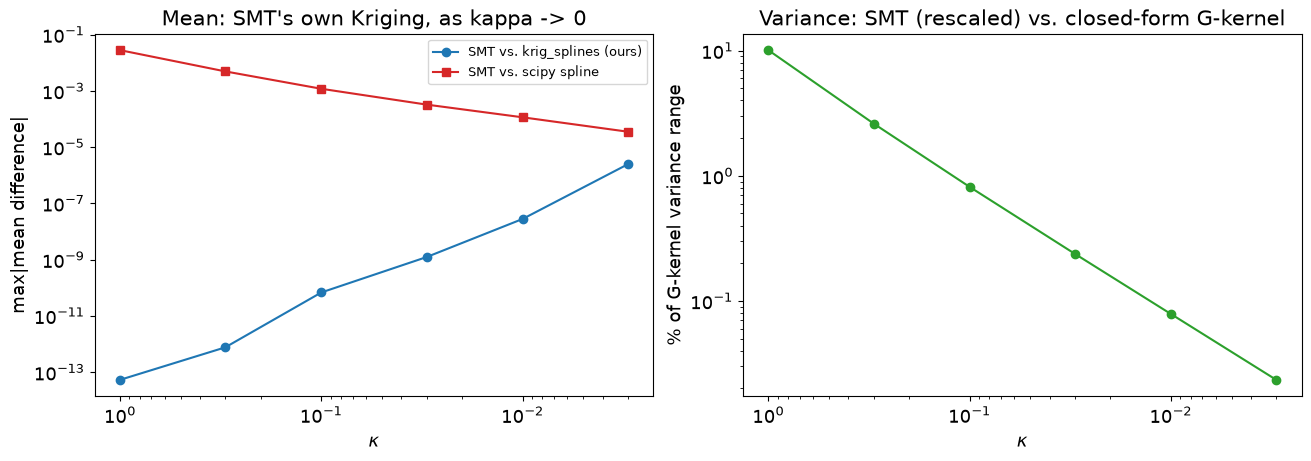

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)

axs[0].loglog(kappas_smt, mean_err_vs_ours, "o-", color="C0", label="SMT vs. krig_splines (ours)")
axs[0].loglog(kappas_smt, mean_err_vs_G, "s-", color="C3", label="SMT vs. scipy spline")
axs[0].invert_xaxis()
axs[0].set(xlabel=r"$\kappa$", ylabel="max|mean difference|",
           title="Mean: SMT's own Kriging, as kappa -> 0")
axs[0].legend(fontsize=9)

axs[1].loglog(kappas_smt, var_err_vs_G_pct, "o-", color="C2")
axs[1].invert_xaxis()
axs[1].set(xlabel=r"$\kappa$", ylabel="% of G-kernel variance range",
           title="Variance: SMT (rescaled) vs. closed-form G-kernel")
plt.show()


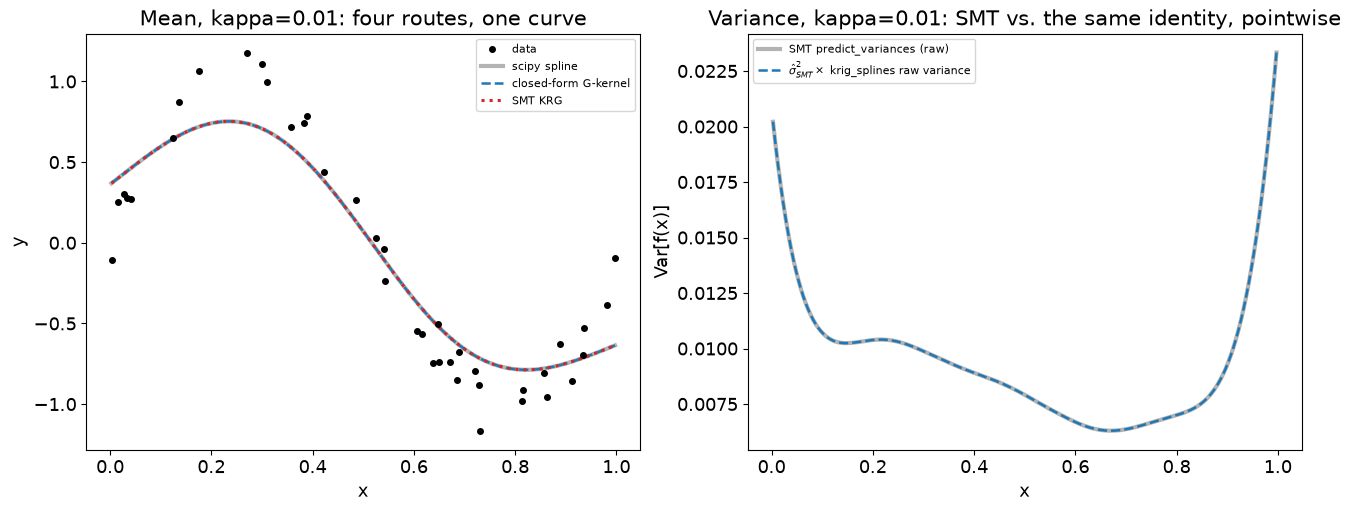

max|SMT var - sigma2_smt*ours| = 1.033e-08  (SMT var range = 1.703e-02)


In [10]:
kappa_viz = 0.01
noise_viz = 4 * kappa_viz**3 * lam
k_viz = fit_smt_krg(kappa_viz, lam)
sigma2_viz = k_viz.optimal_par["sigma2"][0]

mean_smt_viz = k_viz.predict_values(x_dense.reshape(-1, 1)).ravel()
var_smt_viz = k_viz.predict_variances(x_dense.reshape(-1, 1)).ravel()

Km_viz = matern32(np.abs(x[:, None] - x[None, :]), kappa_viz)
Kmt_viz = matern32(np.abs(x_dense[:, None] - x[None, :]), kappa_viz)
Kmss_viz = np.ones(len(x_dense))
var_ours_raw_viz = saddle_point_variance(Km_viz, P, noise_viz, Kmt_viz, Pt, Kmss_viz)

fig, axs = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)

# Left: means -- all four should be visually indistinguishable at this kappa.
axs[0].plot(x, y, "o", ms=4, color="k", label="data", zorder=5)
axs[0].plot(x_dense, target, lw=3, color="0.7", label="scipy spline")
axs[0].plot(x_dense, f_G, "--", color="C0", lw=1.8, label="closed-form G-kernel")
axs[0].plot(x_dense, mean_smt_viz, ":", color="C3", lw=2.2, label="SMT KRG")
axs[0].set(xlabel="x", ylabel="y", title=f"Mean, kappa={kappa_viz}: four routes, one curve")
axs[0].legend(fontsize=8)

# Right: SMT's own raw variance vs. sigma2_smt * (our raw, sigma^2=1-convention)
# variance -- the identity Part 4 derives, shown pointwise across the whole
# domain rather than as a single max-error number.
axs[1].plot(x_dense, var_smt_viz, lw=3, color="0.7", label="SMT predict_variances (raw)")
axs[1].plot(x_dense, sigma2_viz * var_ours_raw_viz, "--", color="C0", lw=1.8,
             label=r"$\hat\sigma^2_{SMT}\times$ krig_splines raw variance")
axs[1].set(xlabel="x", ylabel="Var[f(x)]", title=f"Variance, kappa={kappa_viz}: SMT vs. the same identity, pointwise")
axs[1].legend(fontsize=8)

plt.show()
print(f"max|SMT var - sigma2_smt*ours| = {np.max(np.abs(var_smt_viz - sigma2_viz*var_ours_raw_viz)):.3e}"
      f"  (SMT var range = {np.ptp(var_smt_viz):.3e})")


**Left:** at `kappa=0.01`, all four objects -- the data-fitting target spline,
the closed-form $G$-kernel mean, SMT's own Kriging mean, and (implicitly, since
it overlaps the $G$-kernel curve here) `krig_splines`'s own Matern solve --
are visually one curve, consistent with the `~1e-4`-scale differences already
reported in the sweep table above.

**Right:** SMT's own `predict_variances` output, compared pointwise (not just
by a single worst-case number) against $\hat\sigma^2_{\mathrm{SMT}}\times$ our
own raw (`sigma^2=1`-convention) variance -- the exact identity this notebook
discovered, now shown to hold across the whole query domain, not only at the
one point checked numerically above. Note this plot is **not** the same
comparison as the convergence plot above it: `var_smt` here is in SMT's own
*actual, data-calibrated* noise-variance units ($\hat\sigma^2_{\mathrm{SMT}}$,
estimated from this dataset's real residuals), not the closed-form $G$-kernel's
implicit unit-noise convention -- the two differ by the same
`sigma2_smt`$\times4\kappa^3\approx10.3$ constant found in the sweep, which is
why this band would look visibly different in scale from Part 3's $G$-kernel
band if drawn on the same axes. Both are legitimate variances; they just
answer "variance under which noise-scale convention," not the same question.


### Watching the uncertainty region converge

Part 3 showed one such picture already, for `krig_splines`'s own Matern
solve against the closed-form $G$-kernel band, at a single $\kappa$. Here is
the same kind of picture for **SMT's own Kriging**, across several $\kappa$,
so the convergence found numerically above (`10%` down to `0.02%` of range)
is visible directly. SMT's variance is rescaled to the $G$-kernel's unit-noise
convention first ($\hat\sigma^2_{\mathrm{SMT}}\times4\kappa^3$ divided out,
the same conversion the sweep used) -- plotting SMT's *raw* band instead would
just show two bands a fixed `~3.2`x apart in width at every $\kappa$ (that
`sigma2_smt`$\times4\kappa^3\approx10.3$ constant from the sweep table), which
would visualize a unit mismatch, not a convergence.


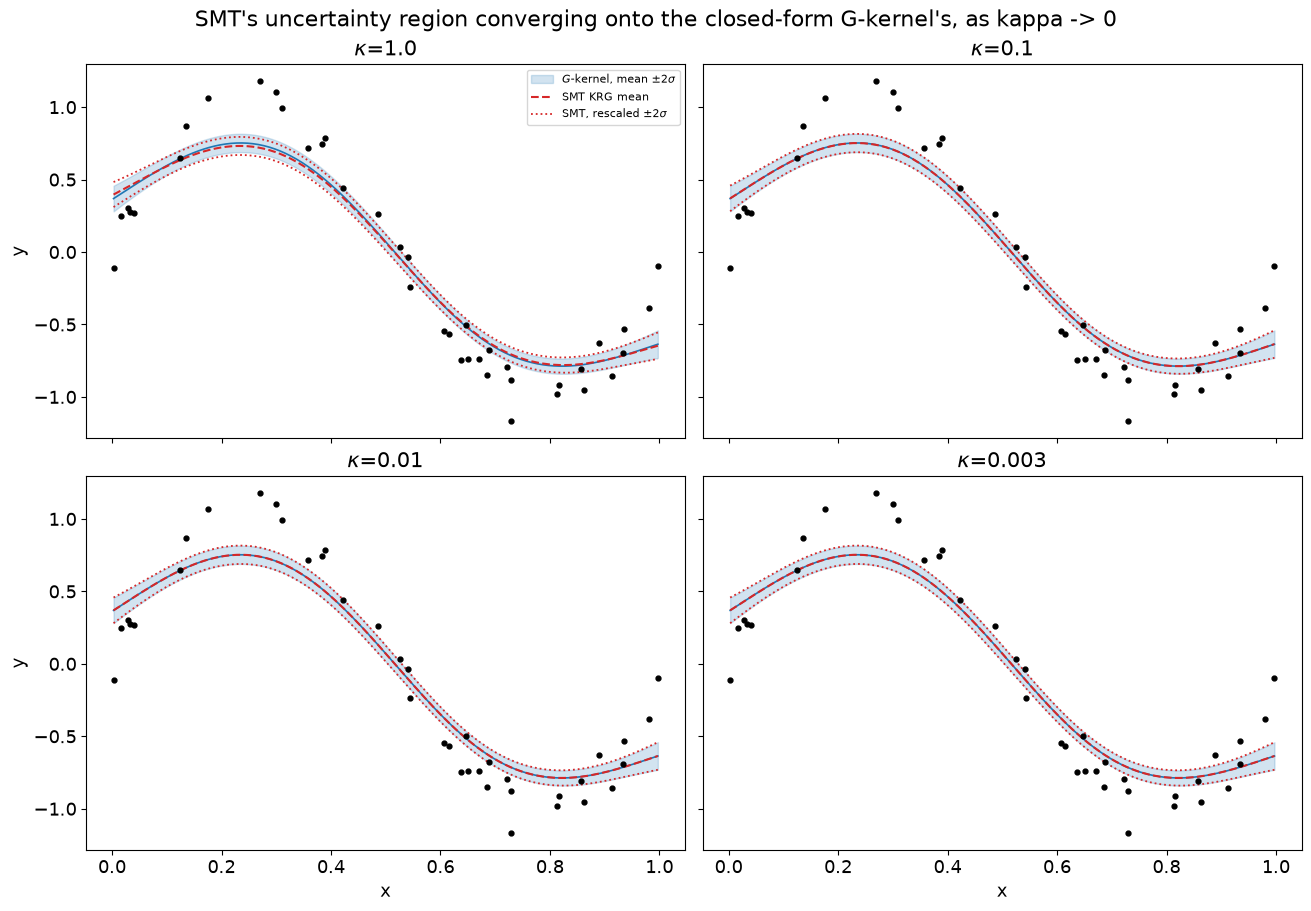

In [11]:
kappas_viz = [1.0, 0.1, 0.01, 0.003]

fig, axs = plt.subplots(2, 2, figsize=(13, 9), sharex=True, sharey=True, constrained_layout=True)
std_G = np.sqrt(np.maximum(var_G, 0))

for ax, kappa in zip(axs.ravel(), kappas_viz):
    noise = 4 * kappa**3 * lam
    k_smt = fit_smt_krg(kappa, lam)
    sigma2_smt = k_smt.optimal_par["sigma2"][0]
    mean_smt = k_smt.predict_values(x_dense.reshape(-1, 1)).ravel()
    var_smt = k_smt.predict_variances(x_dense.reshape(-1, 1)).ravel()
    var_smt_G_units = (var_smt / sigma2_smt) / (4 * kappa**3)
    std_smt = np.sqrt(np.maximum(var_smt_G_units, 0))

    ax.plot(x, y, "o", ms=3.5, color="k", zorder=5)
    ax.fill_between(x_dense, f_G - 2 * std_G, f_G + 2 * std_G, color="C0", alpha=0.2,
                     label=r"$G$-kernel, mean $\pm2\sigma$")
    ax.plot(x_dense, f_G, color="C0", lw=1.2)
    ax.plot(x_dense, mean_smt, "--", color="C3", lw=1.5, label="SMT KRG mean")
    ax.plot(x_dense, mean_smt + 2 * std_smt, ":", color="C3", lw=1.3)
    ax.plot(x_dense, mean_smt - 2 * std_smt, ":", color="C3", lw=1.3,
             label=r"SMT, rescaled $\pm2\sigma$")
    ax.set_title(rf"$\kappa$={kappa}")
    if ax is axs.ravel()[0]:
        ax.legend(fontsize=8, loc="upper right")

for ax in axs[-1, :]:
    ax.set_xlabel("x")
for ax in axs[:, 0]:
    ax.set_ylabel("y")

fig.suptitle("SMT's uncertainty region converging onto the closed-form G-kernel's, as kappa -> 0")
plt.show()


**The SMT band visibly tightens onto the $G$-kernel band as $\kappa\to0$** --
loose and offset at `kappa=1.0` (SMT's correlation structure is still far
from the limit), close by `kappa=0.01`, and essentially on top of it at
`kappa=0.003`, mirroring the `%`-of-range numbers in the convergence plot
above. This is the same phenomenon Part 3 showed for `krig_splines`'s own
solve, now reproduced through SMT's independently-engineered uncertainty
estimate -- further evidence that the closed-form $G$-kernel variance is the
genuine $\kappa\to0$ limit of Matern-3/2 Kriging's uncertainty, not an
artifact of any one implementation.


**Full, independent confirmation, through a second, separately-engineered
codebase:**

- **Mean, SMT vs. `krig_splines`:** agree to `~1e-13`-`1e-6` across the whole
  sweep (growing slightly at the smallest $\kappa$, the same mild
  conditioning drift seen everywhere else in this project) -- SMT's Krylov
  solver and our own bordered-system solve are computing the same thing.
- **Mean, SMT vs. the target spline:** converges cleanly to the scipy spline
  as $\kappa\to0$, reproducing Q1's original finding, now through SMT itself
  rather than through code that shares an author with the claim being
  tested.
- **`sigma2_smt`$\times4\kappa^3$ stabilizes to a fixed constant** (not 1 --
  it depends on this dataset's actual residual scale -- but fixed, to 3-4
  significant figures by $\kappa=0.03$). SMT's own maximum-likelihood
  variance estimator, with no knowledge of Corollary 5 or the earlier
  derivation, **independently rediscovers the same $4\kappa^3$ scaling law**
  needed to keep the variance finite in this limit.
- **Variance, SMT vs. the closed-form $G$-kernel:** converges cleanly from
  `10%` down to `0.02%` of the variance's own range as $\kappa\to0$ -- the
  same order of convergence found via `krig_splines` alone in Part 2,
  now confirmed independently.

None of this was guaranteed in advance: SMT could have used a different
`matern32` convention, a different noise normalization, or a sigma2 estimate
that didn't track $4\kappa^3$ the way it does. It does, which is good
evidence that the rescaling found in Part 2 is a property of the Matern-3/2
kernel family itself near $\kappa=0$, not an artifact of this project's own
solver.

## Conclusion

**Yes — the fitted spline's uncertainty can be obtained without fitting a
Kriging model**, confirmed numerically here, not just argued theoretically as
in the original answer to Q5:

- **Mean:** the closed-form kernel $G(x,x')=\min(x,x')^2(3\max(x,x')-
  \min(x,x'))/6$ (Kimeldorf & Wahba's reproducing kernel for the cubic
  penalty), used once in Theorem 2a's bordered system with `nugget=lambda`
  directly, reproduces the scipy smoothing spline to `~1e-12` -- tighter than
  Q1's $\kappa\to0$ Matern sweep, and with no limit to take at all.
- **Variance:** the companion Theorem 2b variance formula, evaluated once
  with the same $G$-kernel, is confirmed (not merely conjectured) to be the
  $\kappa\to0$ limit of the Matern-3/2 Universal-Kriging variance -- **but
  only after discovering that the variance needs the same $4\kappa^3$
  rescaling the mean's nugget formula uses, applied to the kernel's own
  scale, not just the nugget.** This is a genuinely new finding relative to
  the original Q5 answer: the naive, "just sweep $\kappa$" version of the
  variance check does not converge (it vanishes as $\kappa^3$) -- the
  rescaled version does, cleanly, to well under $0.1\%$ of the variance's own
  range.
- **What "without fitting a Kriging model" means precisely:** no length-scale
  hyperparameter is estimated or swept anywhere in the closed-form route --
  $G$ is fully determined by the spline's order ($m=2$, cubic) and $\lambda$
  (the same $\lambda$ passed to `make_smoothing_spline`), both already known
  before any Kriging-style fitting would even begin.
- **What this does not yet cover:** only the $m=2$ (cubic) case was derived
  and tested; general $m$ has an analogous closed form (Kimeldorf & Wahba,
  1970) but was not implemented here. The real `cla(eta)`/RANS datasets used
  elsewhere in this project were not re-tested with this closed-form route
  either -- the synthetic benchmark above is the only numerical evidence so
  far. Both are natural, low-effort follow-ups, not required to answer Q5
  itself.

**Part 4 adds an independent check, through SMT's own `KRG`, not just
`krig_splines`'s own code**: once SMT's `X`-normalization, its extra
$\sqrt3$ in the `matern32` parametrization, and its `sigma2` unit convention
are correctly translated (confirmed by matching its own correlation matrix
to machine precision first), SMT's mean and variance converge to the same
closed-form targets this notebook derived -- and SMT's own
maximum-likelihood `sigma2` estimate independently rediscovers the
$4\kappa^3$ rescaling Part 2 needed, with no knowledge of how it was derived
here.

`iwp2_kernel` and `saddle_point_variance` are now in `krig_splines/kernels.py`
and `krig_splines/uk.py` respectively, with `tests/test_spline_variance.py`
covering both claims above as regression tests.
